## **6CS012 Artificial Intelligence and Machine Learning - Vision Task**

### **Flower Species Classification Using Convolutional Neural Networks and Transfer Learning**

**Name:** Luniva Shrestha  
**Student Number:** 2433240  
**Group Name:** L6CG23  
**Tutor:** Bijaya Ghimire  
**Module Leader:** Siman Giri

### **Introduction:**
This task involves developing a deep learning model to classify flower images into five species: daisy, dandelion, rose, sunflower, and tulip. Convolutional Neural Networks (CNNs) and transfer learning will be used to extract features and improve classification accuracy, with the aim of building an effective image classification system.

### **Dataset Description:**
Flower Classification Dataset

### **Source:**
https://drive.google.com/drive/folders/1Ke5igoZW7dF4IYnOCjUJpNTgBhWADV2Y

### **1: Importing necessary Libraries**

In [ ]:
import os
import shutil
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# TensorFlow and Keras for deep learning model building
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization,
    GlobalAveragePooling2D, Input
)
from tensorflow.keras.optimizers import SGD, Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array

# Pre-trained model
from tensorflow.keras.applications import MobileNetV2

# Evaluation metrics for classification performance
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score
)

# Training callbacks
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ReduceLROnPlateau

# Model utilities
from tensorflow.keras.models import Model
from sklearn.utils import class_weight
from tensorflow.keras.regularizers import l2

# Image processing library
from PIL import Image

# Google Colab
from google.colab import drive

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

# Initialization message
print("All necessary libraries imported successfully")

All necessary libraries imported successfully


### **2: Mount Drive and Extract Dataset**

#### **2.1: Mount Drive**

In [ ]:
# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


#### **2.2: Load and Extract Dataset**

In [ ]:
# Dataset path in Google Drive
source_path = '/content/drive/MyDrive/6CS012_AI/Flower_Classification'

# Local dataset path
destination_path = './dataset/Flower_Classification'

# Create folder if not exists
os.makedirs(os.path.dirname(destination_path), exist_ok=True)

# Remove old dataset if exists
if os.path.exists(destination_path):
    shutil.rmtree(destination_path)

# Copy dataset to local folder
shutil.copytree(source_path, destination_path)

# Done message
print(f"Dataset copied from {source_path} to {destination_path} successfully.")

Dataset copied from /content/drive/MyDrive/6CS012_AI/Flower_Classification to ./dataset/Flower_Classification successfully.


### **Part A: Designing and Analyzing Convolutional Neural Networks from Scratch.**

### **3: Dataset Path & Initial Analysis**

In [ ]:
# Dataset path
dataset_path = "dataset/Flower_Classification"
train_dir = os.path.join(dataset_path, "Train")
test_dir = os.path.join(dataset_path, "Test")

# Get class names
classes = sorted([
    cls for cls in os.listdir(train_dir)
    if not cls.startswith(".")
])

# Count images per class (train)
train_class_counts = {
    cls: len(os.listdir(os.path.join(train_dir, cls)))
    for cls in classes
}

# Total train images
total_train_images = sum(train_class_counts.values())

# Total test images
total_test_images = sum(
    1 for f in os.listdir(test_dir)
    if os.path.isfile(os.path.join(test_dir, f))
)

# Total images
total_images = total_train_images + total_test_images

# Print dataset info
print(f"Number of Classes: {len(classes)}")
print(f"Classes: {classes}")
print(f"Total Training Images: {total_train_images}")
print(f"Training Images per Class: {train_class_counts}")
print(f"Total Test Images: {total_test_images}")
print(f"Total Images (Train + Test): {total_images}")

# Store class counts
class_counts = train_class_counts

Number of Classes: 5
Classes: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Total Training Images: 4312
Training Images per Class: {'daisy': 763, 'dandelion': 1051, 'rose': 783, 'sunflower': 732, 'tulip': 983}
Total Test Images: 5
Total Images (Train + Test): 4317


*   **Dataset Representation:** The dataset contains images of five flower species: daisy, dandelion, rose, sunflower, and tulip, used for multi-class classification.
*   **Total Images:** There are 4317 images in total (4312 training, 5 test).
*   **Class Distribution:** The training data is relatively balanced across all classes.
*   **Dataset Split:** An 80/20 training-validation split was applied using ImageDataGenerator to evaluate model generalization.

### **4: Dataset Overview**

#### **4.1: Class Distribution**

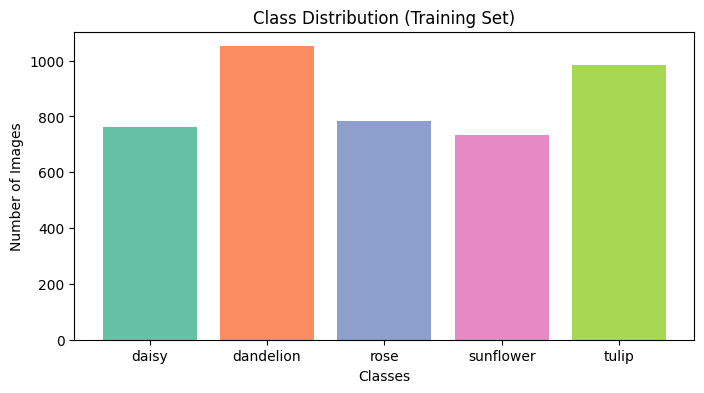

In [ ]:
# Colors for each class
colors = sns.color_palette("Set2", len(class_counts))

# Plot class distribution
plt.figure(figsize=(8,4))
plt.bar(class_counts.keys(), class_counts.values(), color=colors)

# Labels and title
plt.title("Class Distribution (Training Set)")
plt.xlabel("Classes")
plt.ylabel("Number of Images")

# Show plot
plt.show()

#### **4.2: Sample Images**

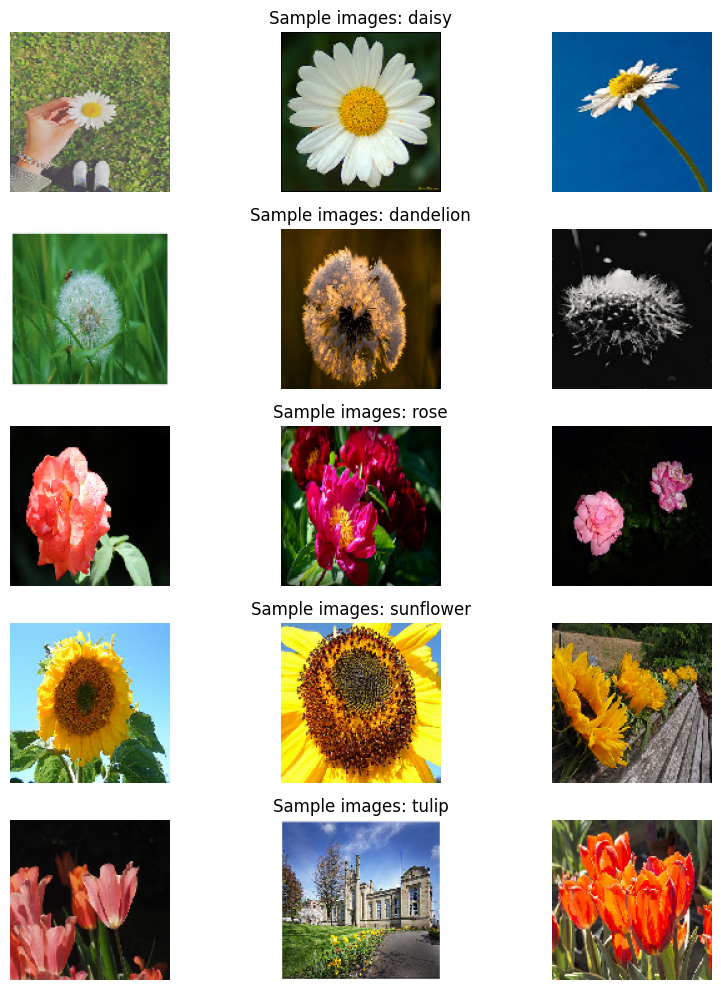

In [ ]:
# Show sample images from each class
def show_samples(train_dir, classes, n=3):
    num_classes = len(classes)
    images_per_class = n

    # Create subplot grid
    fig, axes = plt.subplots(
        num_classes, images_per_class,
        figsize=(3 * images_per_class, 2 * num_classes)
    )

    # Fix axes shape for single row/column cases
    if num_classes == 1:
        axes = [axes]
    if images_per_class == 1:
        for i in range(num_classes):
            axes[i] = [axes[i]]

    # Loop through each class
    for i, cls in enumerate(classes):
        img_list = os.listdir(os.path.join(train_dir, cls))[:images_per_class]

        # Display images
        for j, img_name in enumerate(img_list):
            img_path = os.path.join(train_dir, cls, img_name)
            img = load_img(img_path, target_size=(128, 128))

            ax = axes[i][j]
            ax.imshow(img)
            ax.axis("off")

            # Add class title
            if j == 1:
                ax.set_title(f"Sample images: {cls}")

    plt.tight_layout()
    plt.show()


# Run sample visualization
show_samples(train_dir, classes)

### **5: Data Preprocessing**

#### **5.1: Data Cleaning**

In [ ]:
# Remove corrupted images from dataset
def clean_images(folder):
    for root, _, files in os.walk(folder):
        for file in files:
            path = os.path.join(root, file)
            try:
                img = Image.open(path)
                img.verify()
            except:
                print("Removing corrupted file:", path)
                os.remove(path)

# Run cleaning on training dataset
clean_images("dataset/Flower_Classification/Train")

Removing corrupted file: dataset/Flower_Classification/Train/.DS_Store
Removing corrupted file: dataset/Flower_Classification/Train/tulip/16702188449_3dacce90b2_m.jpg
Removing corrupted file: dataset/Flower_Classification/Train/tulip/6931715360_34edc5a372_m.jpg
Removing corrupted file: dataset/Flower_Classification/Train/tulip/7082608511_f4cf233f59_n.jpg
Removing corrupted file: dataset/Flower_Classification/Train/tulip/2087981909_fd468de5c4_n.jpg
Removing corrupted file: dataset/Flower_Classification/Train/tulip/5661431592_cea1108261_n.jpg
Removing corrupted file: dataset/Flower_Classification/Train/tulip/14487762578_baba13d16a_m.jpg
Removing corrupted file: dataset/Flower_Classification/Train/tulip/12584810723_c97d00fcfd.jpg
Removing corrupted file: dataset/Flower_Classification/Train/dandelion/2995221296_a6ddaccc39.jpg
Removing corrupted file: dataset/Flower_Classification/Train/dandelion/34323645656_afd53a9996_n.jpg
Removing corrupted file: dataset/Flower_Classification/Train/dande

#### **5.2: Data Augmentation**

##### **5.2.1: Train (augmentation included) and Train vs Validation Split**

In [ ]:
# Image settings
IMG_SIZE = (128,128)
BATCH_SIZE = 32

# Train folder path
base_data_for_split = os.path.join(dataset_path, "Train")

# Data augmentation + preprocessing
train_gen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.2
)

# Training data generator
train_data = train_gen.flow_from_directory(
    base_data_for_split,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

Found 3423 images belonging to 5 classes.


*   **Preprocessing:** Images are resized to 128×128 pixels and normalized (scaled to [0,1]) for consistent CNN input.
*   **Data Generators:** ImageDataGenerator is used for preprocessing and augmentation.
*   **Data Augmentation:** Rotation, shifting, shearing, zooming, and horizontal flipping are applied to increase data diversity and reduce overfitting.

##### **5.2.2: Augmented image visualization**

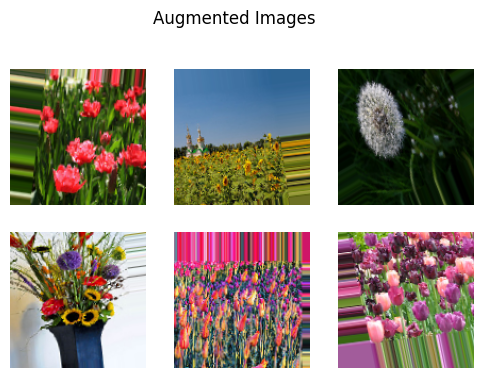

In [ ]:
# Get a batch of images
x, y = next(train_data)

# Plot augmented images
plt.figure(figsize=(6,6))

for i in range(6):
    plt.subplot(3,3,i+1)
    plt.imshow(x[i])
    plt.axis("off")

# Title
plt.suptitle("Augmented Images")
plt.show()

##### **5.2.3: Validation (No augmentation)**

In [ ]:
# Validation data generator
val_data = train_gen.flow_from_directory(
    base_data_for_split,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

Found 854 images belonging to 5 classes.


##### **5.2.4: Updated Class Distribution After Splitting and Cleaning**

In [ ]:
# Get class names
class_names = list(train_data.class_indices.keys())

# Count training samples per class
train_counts = pd.Series(train_data.classes).map(lambda x: class_names[x]).value_counts().sort_index()

# Count validation samples per class
val_counts = pd.Series(val_data.classes).map(lambda x: class_names[x]).value_counts().sort_index()

# Convert to dictionary format
training_dict = train_counts.to_dict()
validation_dict = val_counts.to_dict()

# Print dataset info
print("Train samples:", train_data.samples)
print("Validation samples:", val_data.samples)
print("\nClass Indices:", train_data.class_indices)

print("\nTraining Images per Class:", training_dict)
print("Validation Images per Class:", validation_dict)

Train samples: 3423
Validation samples: 854

Class Indices: {'daisy': 0, 'dandelion': 1, 'rose': 2, 'sunflower': 3, 'tulip': 4}

Training Images per Class: {'daisy': 605, 'dandelion': 836, 'rose': 621, 'sunflower': 580, 'tulip': 781}
Validation Images per Class: {'daisy': 151, 'dandelion': 208, 'rose': 155, 'sunflower': 145, 'tulip': 195}


### **6: Model Development**

#### **6.1: Calculate class weights to handle imbalance**

In [ ]:
# Calculate class weights to handle imbalance
class_indices = train_data.class_indices
labels = train_data.classes

# Compute balanced class weights
weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(labels),
    y=labels
)

# Convert to dictionary format
class_weight_dict = dict(enumerate(weights))

# Print class weights
print("Class Weights:", class_weight_dict)

Class Weights: {0: np.float64(1.1315702479338843), 1: np.float64(0.8188995215311005), 2: np.float64(1.1024154589371982), 3: np.float64(1.180344827586207), 4: np.float64(0.8765685019206146)}


#### **6.2: Baseline CNN Model**

##### **6.2.1: Build Baseline CNN Model**

In [ ]:
# Baseline CNN model
def build_baseline(num_classes):
    model = Sequential([
        Input(shape=(128, 128, 3)),

        Conv2D(32, (3, 3), activation='relu'),
        MaxPooling2D(2, 2),

        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D(2, 2),

        Conv2D(128, (3, 3), activation='relu'),
        MaxPooling2D(2, 2),

        Flatten(),

        Dense(128, activation='relu'),
        Dense(64, activation='relu'),
        Dense(32, activation='relu'),

        Dense(num_classes, activation='softmax')
    ])
    return model

# Number of output classes
num_classes = len(classes)

# Create model
baseline = build_baseline(num_classes)

# Compile model
baseline.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Show model architecture
baseline.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,315,141 (12.65 MB)

 Trainable params: 3,315,141 (12.65 MB)

 Non-trainable params: 0 (0.00 B)

**Baseline Model - Architecture Interpretation**

*   **Model Summary:** A Sequential CNN with three convolutional blocks (Conv2D + MaxPooling2D) is used for feature extraction, with filters increasing from 32 to 128 and ReLU activation.
*   **Fully Connected Layers:** The extracted features are flattened and passed through three dense layers (128, 64, 32 neurons) for classification.
*   **Output Layer:** A final dense layer with 5 neurons and softmax activation outputs class probabilities.

##### **6.2.2: Train Baseline CNN Model**

In [ ]:
# Early stopping to avoid overfitting
early_stop_baseline = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)

# Reduce learning rate when model plateaus
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=0.00001, verbose=1)

# Start training
print("Starting Baseline Model Training...")
start_time = time.time()

h1 = baseline.fit(
    train_data,
    validation_data=val_data,
    epochs=50,
    class_weight=class_weight_dict,
    callbacks=[early_stop_baseline, reduce_lr]
)

# Training time
baseline_time = time.time() - start_time
print(f"Total training time: {baseline_time:.2f} seconds")

Starting Baseline Model Training...
Epoch 1/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 40s 295ms/step - accuracy: 0.4102 - loss: 1.2955 - val_accuracy: 0.4848 - val_loss: 1.2512 - learning_rate: 0.0010
Epoch 2/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 24s 224ms/step - accuracy: 0.5440 - loss: 1.0862 - val_accuracy: 0.5773 - val_loss: 1.0438 - learning_rate: 0.0010
Epoch 3/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 26s 240ms/step - accuracy: 0.6109 - loss: 0.9705 - val_accuracy: 0.6089 - val_loss: 0.9600 - learning_rate: 0.0010
Epoch 4/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 25s 236ms/step - accuracy: 0.6407 - loss: 0.9119 - val_accuracy: 0.6546 - val_loss: 0.8949 - learning_rate: 0.0010
Epoch 5/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 30s 281ms/step - accuracy: 0.6509 - loss: 0.8923 - val_accuracy: 0.6756 - val_loss: 0.8452 - learning_rate: 0.0010
Epoch 6/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 30s 284ms/step - accuracy: 0.6889 - loss: 0.8177 - val_accuracy: 0.6745 - val_loss: 0.8520 - learning_rate: 0.0010
Epoch 7/50
107/107 ━━━━━━━━━━━━━━━

##### **6.2.2: Baseline Curves**

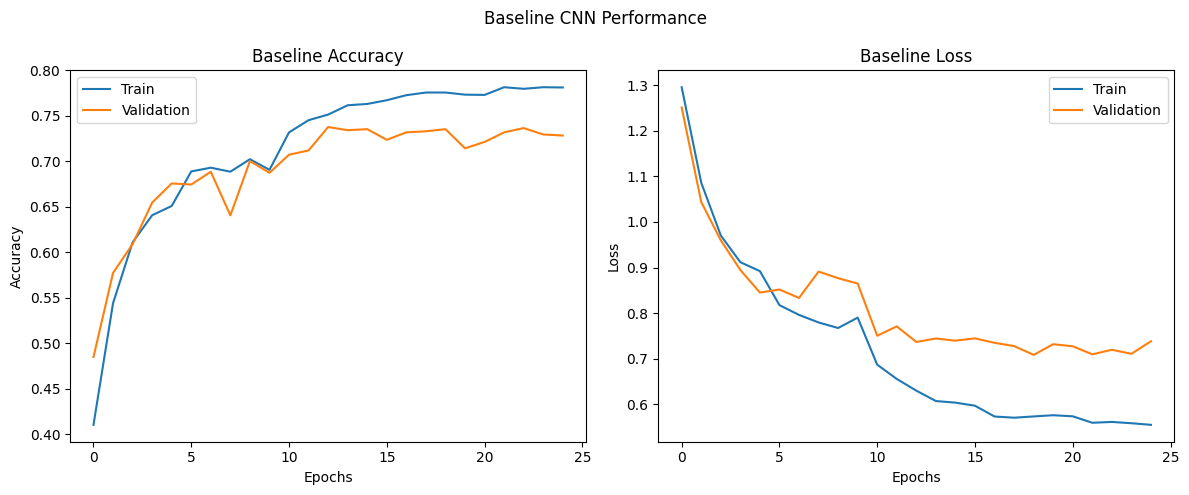

In [ ]:
# Plot training accuracy and loss
plt.figure(figsize=(12,5))

# Accuracy plot
plt.subplot(1,2,1)
plt.plot(h1.history['accuracy'], label='Train')
plt.plot(h1.history['val_accuracy'], label='Validation')
plt.title("Baseline Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

# Loss plot
plt.subplot(1,2,2)
plt.plot(h1.history['loss'], label='Train')
plt.plot(h1.history['val_loss'], label='Validation')
plt.title("Baseline Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

# Overall title
plt.suptitle("Baseline CNN Performance")

plt.tight_layout()
plt.show()

##### **6.2.3: Baseline Model Evaluation**

In [ ]:
# Predict validation data
y_pred_base = np.argmax(baseline.predict(val_data), axis=1)
y_true_base = val_data.classes

# Evaluation report
print("Baseline Model Evaluation:")
print(classification_report(y_true_base, y_pred_base))

27/27 ━━━━━━━━━━━━━━━━━━━━ 6s 202ms/step
Baseline Model Evaluation:
              precision    recall  f1-score   support

           0       0.82      0.79      0.81       151
           1       0.81      0.78      0.79       208
           2       0.57      0.66      0.61       155
           3       0.70      0.83      0.76       145
           4       0.76      0.61      0.68       195

    accuracy                           0.73       854
   macro avg       0.73      0.73      0.73       854
weighted avg       0.74      0.73      0.73       854



##### **6.2.4:  Confusion Matrix**

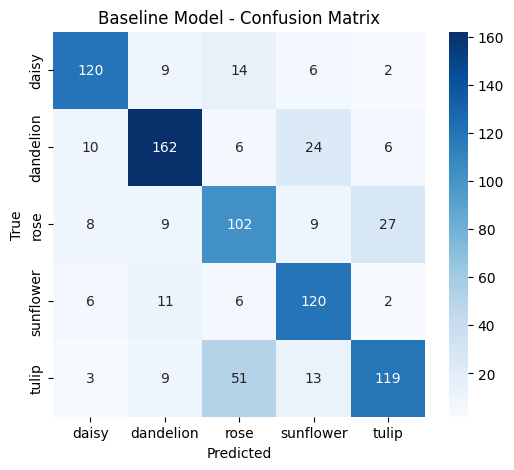

In [ ]:
# Confusion matrix
cm = confusion_matrix(y_true_base, y_pred_base)

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)

# Labels and title
plt.title('Baseline Model - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')

plt.show()

##### **6.2.5:  Inference on Images (Baseline Model)**

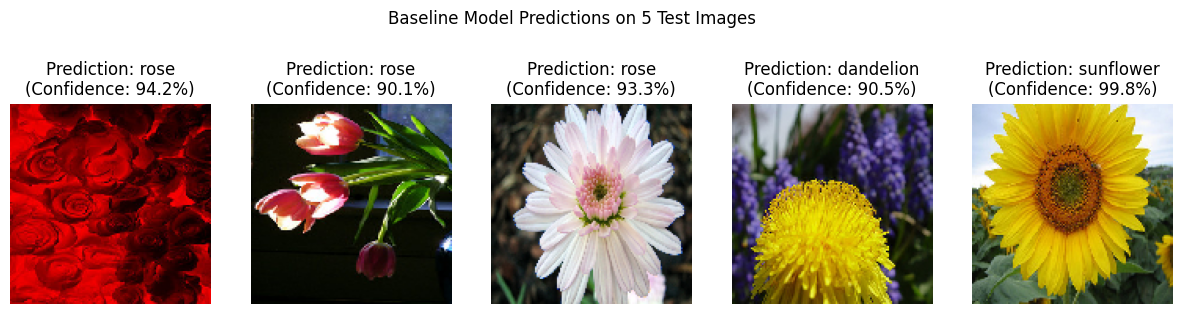

In [ ]:
# Test images path
original_test_dir = os.path.join(dataset_path, "Test")

# Get sorted test images
test_images = sorted([f for f in os.listdir(original_test_dir) if os.path.isfile(os.path.join(original_test_dir, f))])

# Plot predictions
plt.figure(figsize=(15, 4))

for i, img_name in enumerate(test_images):
    img_path = os.path.join(original_test_dir, img_name)
    img = load_img(img_path, target_size=(128, 128))
    img_array = img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Model prediction
    prediction = baseline.predict(img_array, verbose=0)
    pred_idx = np.argmax(prediction)
    pred_class = classes[pred_idx]
    confidence = np.max(prediction) * 100

    # Display image with prediction
    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(f"Prediction: {pred_class}\n(Confidence: {confidence:.1f}%)")
    plt.axis('off')

# Overall title
plt.suptitle("Baseline Model Predictions on 5 Test Images")
plt.show()

**Baseline Model - Performance Observations**

*   **Key Observations:** The baseline model achieved around 73% validation accuracy. Training and validation curves indicate effective learning, with EarlyStopping helping to limit overfitting.
*   **Inference:** Predictions on test images showed mixed confidence levels, with several correct and highly confident classifications, consistent with overall performance.

#### **6.3: Deeper CNN Model**

##### **6.3.1:  Build Deeper Model**

In [ ]:
# Deeper CNN model with regularization
def build_deeper_model(num_classes, dropout_rate=0.3, regularization=l2(0.001)):

    model = Sequential([

        Input(shape=(128, 128, 3)),

        Conv2D(32, (3,3), activation='relu', padding='same', kernel_regularizer=regularization),
        BatchNormalization(),
        MaxPooling2D(2,2),

        Conv2D(32, (3,3), activation='relu', padding='same', kernel_regularizer=regularization),
        BatchNormalization(),
        MaxPooling2D(2,2),

        Conv2D(64, (3,3), activation='relu', padding='same', kernel_regularizer=regularization),
        BatchNormalization(),
        MaxPooling2D(2,2),

        Conv2D(64, (3,3), activation='relu', padding='same', kernel_regularizer=regularization),
        BatchNormalization(),
        MaxPooling2D(2,2),

        Conv2D(128, (3,3), activation='relu', padding='same', kernel_regularizer=regularization),
        BatchNormalization(),
        MaxPooling2D(2,2),

        Conv2D(128, (3,3), activation='relu', padding='same', kernel_regularizer=regularization),
        BatchNormalization(),
        MaxPooling2D(2,2),

        Flatten(),

        Dense(128, activation='relu', kernel_regularizer=regularization),
        Dropout(dropout_rate),

        Dense(128, activation='relu', kernel_regularizer=regularization),
        Dropout(dropout_rate - 0.1),

        Dense(64, activation='relu', kernel_regularizer=regularization),
        Dropout(dropout_rate - 0.2),

        Dense(64, activation='relu', kernel_regularizer=regularization),

        Dense(32, activation='relu', kernel_regularizer=regularization),

        Dense(32, activation='relu', kernel_regularizer=regularization),

        Dense(num_classes, activation='softmax')
    ])

    return model

# Build model
deeper_model = build_deeper_model(num_classes)

# Compile model
deeper_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Show model summary
deeper_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 4, 4, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 4, 4, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 2, 2, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        16,51

 Total params: 385,637 (1.47 MB)

 Trainable params: 384,741 (1.47 MB)

 Non-trainable params: 896 (3.50 KB)

**Deeper Model - Architecture Interpretation**

*   **Model Summary:** A deeper CNN with six convolutional blocks, each incorporating Batch Normalisation and L2 regularization for improved stability and generalization.
*   **Regularization:** Dropout layers (0.1–0.2) are applied in the fully connected layers to reduce overfitting.
*   **Complexity:** The increased depth and parameters enable the model to capture more complex features.

##### **6.3.1:  Train Deeper Model**

In [ ]:
# Early stopping for deeper model
early_stop_deep = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)

# Reduce learning rate on plateau
reduce_lr_deep = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=0.00001, verbose=1)

# Start training
print("Starting Deeper Model Training...")
start_time = time.time()

h2 = deeper_model.fit(
    train_data,
    validation_data=val_data,
    epochs=50,
    class_weight=class_weight_dict,
    callbacks=[early_stop_deep, reduce_lr_deep]
)

# Training time
deep_time = time.time() - start_time
print(f"Total training time: {deep_time:.2f} seconds")

Starting Deeper Model Training...
Epoch 1/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 53s 360ms/step - accuracy: 0.4335 - loss: 2.1961 - val_accuracy: 0.2436 - val_loss: 3.5629 - learning_rate: 0.0010
Epoch 2/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 25s 236ms/step - accuracy: 0.5481 - loss: 1.8930 - val_accuracy: 0.2436 - val_loss: 3.9705 - learning_rate: 0.0010
Epoch 3/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 23s 219ms/step - accuracy: 0.5855 - loss: 1.7569 - val_accuracy: 0.2646 - val_loss: 2.5243 - learning_rate: 0.0010
Epoch 4/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 25s 237ms/step - accuracy: 0.6173 - loss: 1.6542 - val_accuracy: 0.4192 - val_loss: 2.1779 - learning_rate: 0.0010
Epoch 5/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 25s 237ms/step - accuracy: 0.6386 - loss: 1.5539 - val_accuracy: 0.4801 - val_loss: 1.8716 - learning_rate: 0.0010
Epoch 6/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 25s 233ms/step - accuracy: 0.6655 - loss: 1.4424 - val_accuracy: 0.5574 - val_loss: 1.7148 - learning_rate: 0.0010
Epoch 7/50
107/107 ━━━━━━━━━━━━━━━━━

##### **6.3.2: Deeper Model Curves**

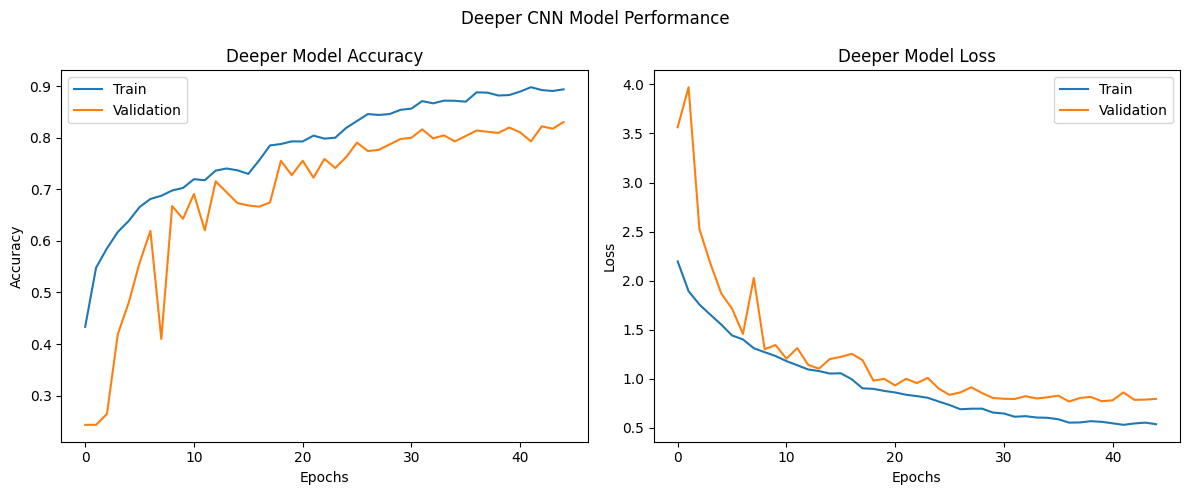

In [ ]:
# Plot deeper model performance
plt.figure(figsize=(12,5))

# Accuracy plot
plt.subplot(1,2,1)
plt.plot(h2.history['accuracy'], label='Train')
plt.plot(h2.history['val_accuracy'], label='Validation')
plt.title("Deeper Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

# Loss plot
plt.subplot(1,2,2)
plt.plot(h2.history['loss'], label='Train')
plt.plot(h2.history['val_loss'], label='Validation')
plt.title("Deeper Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

# Overall title
plt.suptitle("Deeper CNN Model Performance")

plt.tight_layout()
plt.show()

##### **6.3.3: Deeper Model Evaluation**

In [ ]:
# Predict validation data
y_pred_deep = np.argmax(deeper_model.predict(val_data), axis=1)
y_true_deep = val_data.classes

# Evaluation report
print("Deeper Model Evaluation:")
print(classification_report(y_true_deep, y_pred_deep))

27/27 ━━━━━━━━━━━━━━━━━━━━ 7s 240ms/step
Deeper Model Evaluation:
              precision    recall  f1-score   support

           0       0.87      0.87      0.87       151
           1       0.83      0.90      0.87       208
           2       0.76      0.74      0.75       155
           3       0.87      0.85      0.86       145
           4       0.77      0.73      0.75       195

    accuracy                           0.82       854
   macro avg       0.82      0.82      0.82       854
weighted avg       0.82      0.82      0.82       854



##### **6.3.4:  Confusion Matrix**

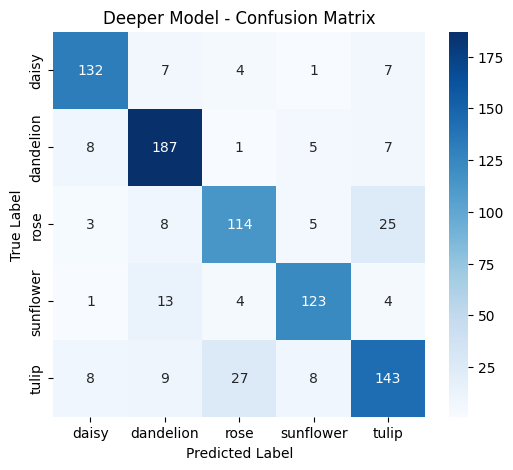

In [ ]:
# Confusion matrix for deeper model
cm_deep = confusion_matrix(y_true_deep, y_pred_deep)

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm_deep, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)

# Labels and title
plt.title('Deeper Model - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.show()

##### **6.3.5:  Inference Block (Deeper Model)**

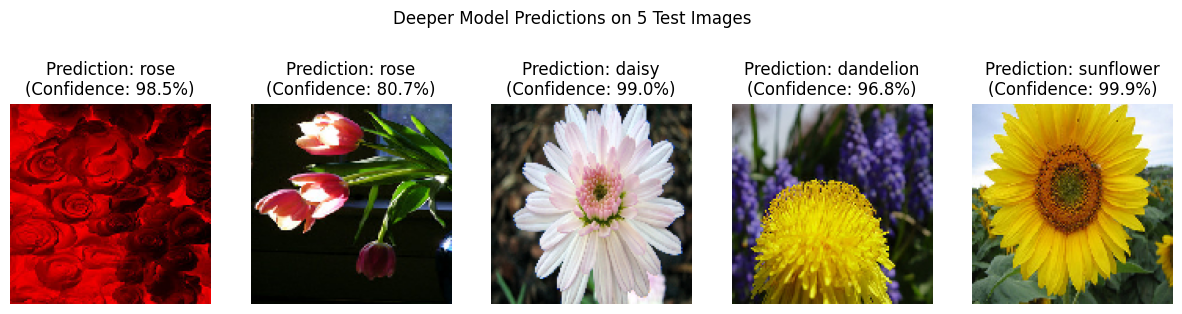

In [ ]:
# Plot predictions for deeper model
plt.figure(figsize=(15, 4))

for i, img_name in enumerate(test_images):
    img_path = os.path.join(original_test_dir, img_name)
    img = load_img(img_path, target_size=(128, 128))
    img_array = img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Model prediction
    prediction = deeper_model.predict(img_array, verbose=0)
    pred_idx = np.argmax(prediction)
    pred_class = classes[pred_idx]
    confidence = np.max(prediction) * 100

    # Display image with prediction
    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(f"Prediction: {pred_class}\n(Confidence: {confidence:.1f}%)")
    plt.axis('off')

# Overall title
plt.suptitle("Deeper Model Predictions on 5 Test Images")
plt.show()

**Deeper Model - Performance Observations**

*   **Performance Comparison:** The deeper model achieved a validation accuracy of approximately 82%, outperforming the baseline's 73%. This suggests that the added layers and regularization helped to improve performance for this dataset.

*   **Training Dynamics:** Validation loss curves showed more fluctuations initially, but the model eventually converged. EarlyStopping played a crucial role in preventing overfitting, allowing the model to achieve better results.

#### **6.4: Compare Models (Baseline vs Deep)**

##### **6.4.1: Summary Comparison Table**

In [ ]:
# Create results table
results = pd.DataFrame({
    "Model": ["Baseline", "Deep"],
    "Accuracy": [
        accuracy_score(y_true_base, y_pred_base),
        accuracy_score(y_true_deep, y_pred_deep)
    ],
    "Precision": [
        precision_score(y_true_base, y_pred_base, average='weighted'),
        precision_score(y_true_deep, y_pred_deep, average='weighted')
    ],
    "Recall": [
        recall_score(y_true_base, y_pred_base, average='weighted'),
        recall_score(y_true_deep, y_pred_deep, average='weighted')
    ],
    "F1": [
        f1_score(y_true_base, y_pred_base, average='weighted'),
        f1_score(y_true_deep, y_pred_deep, average='weighted')
    ]
})

# Display results
display(results)

,Model,Accuracy,Precision,Recall,F1
0,Baseline,0.729508,0.737684,0.729508,0.730046
1,Deep,0.818501,0.817438,0.818501,0.817530


**Experimentation and Comparative Analysis - Baseline vs. Deeper Model**

**Performance:** The deeper model ~0.818 accuracy significantly outperformed the baseline model ~0.729 accuracy. This suggests that the increased complexity, combined with regularization techniques, was effective in improving results for this classification task.

##### **6.4.2: Time Comparison**

In [ ]:
# Compare training times
if deep_time > baseline_time:
    print(f"Deep model took more time: {deep_time:.2f} seconds")
else:
    print(f"Baseline model is slower: {baseline_time:.2f} seconds")

Deep model took more time: 1208.09 seconds


**Experimentation and Comparative Analysis - Computational Efficiency**

*   **Training Time:** The deeper model trained for a longer duration (1208.09s) compared to the baseline (692.51s), reflecting its increased complexity and number of parameters.

*   **Trade-offs:** While taking longer, the deeper model's improved accuracy suggests that the computational cost can be justified by better performance on this specific dataset, demonstrating a typical trade-off between model complexity, training time, and accuracy.

##### **6.4.3: Model Comparison Curves**


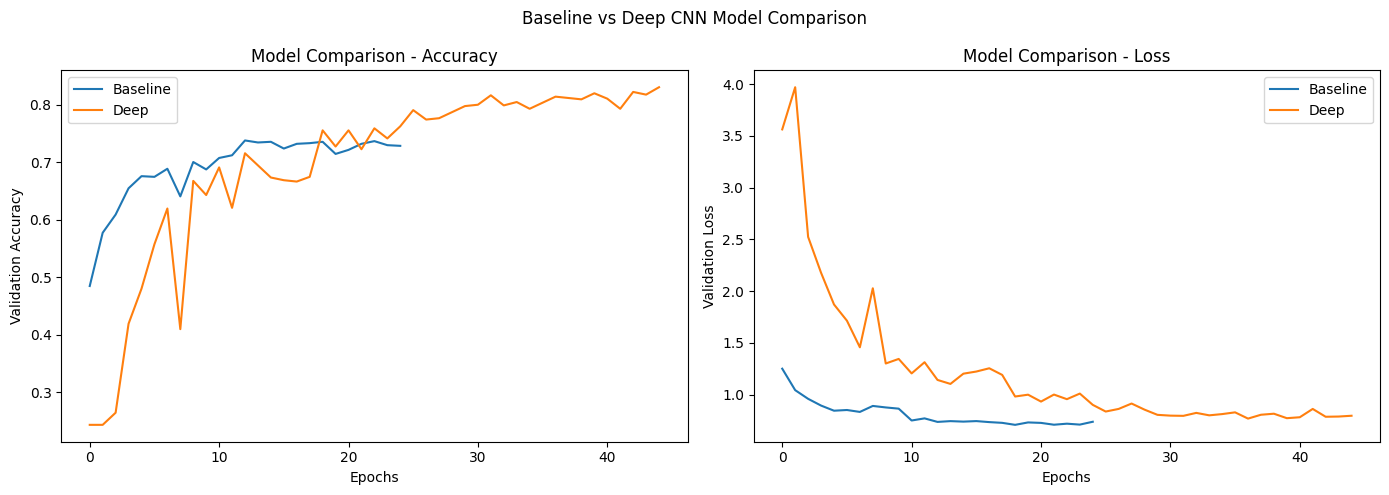

In [ ]:
# Compare baseline vs deeper model
plt.figure(figsize=(14,5))

# Accuracy comparison
plt.subplot(1,2,1)
plt.plot(h1.history['val_accuracy'], label='Baseline')
plt.plot(h2.history['val_accuracy'], label='Deep')
plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.title("Model Comparison - Accuracy")
plt.legend()

# Loss comparison
plt.subplot(1,2,2)
plt.plot(h1.history['val_loss'], label='Baseline')
plt.plot(h2.history['val_loss'], label='Deep')
plt.xlabel("Epochs")
plt.ylabel("Validation Loss")
plt.title("Model Comparison - Loss")
plt.legend()

# Overall title
plt.suptitle("Baseline vs Deep CNN Model Comparison")

plt.tight_layout()
plt.show()

### **7: Optimizer Comparison for Deeper Model (SGD vs Adam)**

#### **7.1: Model Setup for SGD**

In [ ]:
# Build deeper model with SGD
model_sgd = build_deeper_model(num_classes)

# Compile with SGD optimizer
model_sgd.compile(optimizer=SGD(learning_rate=0.01), loss='categorical_crossentropy', metrics=['accuracy'])

# Callbacks
early_stop_model_sgd = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
reduce_lr_compare = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=0.00001, verbose=1)

# Start training
print("Starting Training with SGD Optimizer...")
start_time = time.time()

h_sgd = model_sgd.fit(
    train_data,
    validation_data=val_data,
    epochs=50,
    class_weight=class_weight_dict,
    callbacks=[early_stop_model_sgd, reduce_lr_compare]
)

# Training time
sgd_time = time.time() - start_time
print(f'Total training time (SGD): {sgd_time:.2f} seconds')

Starting Training with SGD Optimizer...
Epoch 1/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 41s 303ms/step - accuracy: 0.2840 - loss: 2.4243 - val_accuracy: 0.2436 - val_loss: 2.4776 - learning_rate: 0.0100
Epoch 2/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 25s 236ms/step - accuracy: 0.4043 - loss: 2.2558 - val_accuracy: 0.2482 - val_loss: 2.4871 - learning_rate: 0.0100
Epoch 3/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 25s 229ms/step - accuracy: 0.4923 - loss: 2.0758 - val_accuracy: 0.2881 - val_loss: 2.4717 - learning_rate: 0.0100
Epoch 4/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 24s 226ms/step - accuracy: 0.5253 - loss: 1.9912 - val_accuracy: 0.4918 - val_loss: 2.0439 - learning_rate: 0.0100
Epoch 5/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 25s 237ms/step - accuracy: 0.5565 - loss: 1.9304 - val_accuracy: 0.5796 - val_loss: 1.8875 - learning_rate: 0.0100
Epoch 6/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 25s 236ms/step - accuracy: 0.5720 - loss: 1.8917 - val_accuracy: 0.5703 - val_loss: 1.9352 - learning_rate: 0.0100
Epoch 7/50
107/107 ━━━━━━━━━━━

#### **7.2: Model Setup for Adam**

In [ ]:
# Build deeper model with Adam
model_adam = build_deeper_model(num_classes)

# Compile with Adam optimizer
model_adam.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])

# Early stopping
early_stop_model_adam = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)

# Start training
print("Starting Training with Adam Optimizer...")
start_time = time.time()

h_adam = model_adam.fit(
    train_data,
    validation_data=val_data,
    epochs=50,
    class_weight=class_weight_dict,
    callbacks=[early_stop_model_adam, reduce_lr_compare]
)

# Training time
adam_time = time.time() - start_time
print(f'Total training time (Adam): {adam_time:.2f} seconds')

Starting Training with Adam Optimizer...
Epoch 1/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 49s 338ms/step - accuracy: 0.4289 - loss: 2.1907 - val_accuracy: 0.2436 - val_loss: 2.7563 - learning_rate: 0.0010
Epoch 2/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 24s 224ms/step - accuracy: 0.5419 - loss: 1.9028 - val_accuracy: 0.2436 - val_loss: 4.1984 - learning_rate: 0.0010
Epoch 3/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step - accuracy: 0.5829 - loss: 1.7754
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
107/107 ━━━━━━━━━━━━━━━━━━━━ 25s 234ms/step - accuracy: 0.5814 - loss: 1.7696 - val_accuracy: 0.2553 - val_loss: 2.8148 - learning_rate: 0.0010
Epoch 4/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 25s 238ms/step - accuracy: 0.6246 - loss: 1.6280 - val_accuracy: 0.3466 - val_loss: 2.1214 - learning_rate: 5.0000e-04
Epoch 5/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 26s 242ms/step - accuracy: 0.6550 - loss: 1.5378 - val_accuracy: 0.5703 - val_loss: 1.7338 - learning_rate: 5.0000e-04
Epoch 6/50
107/107 ━━━━

#### **7.3: Compare Optimizers**

##### **7.3.1: Optimizer Comparison Curves**

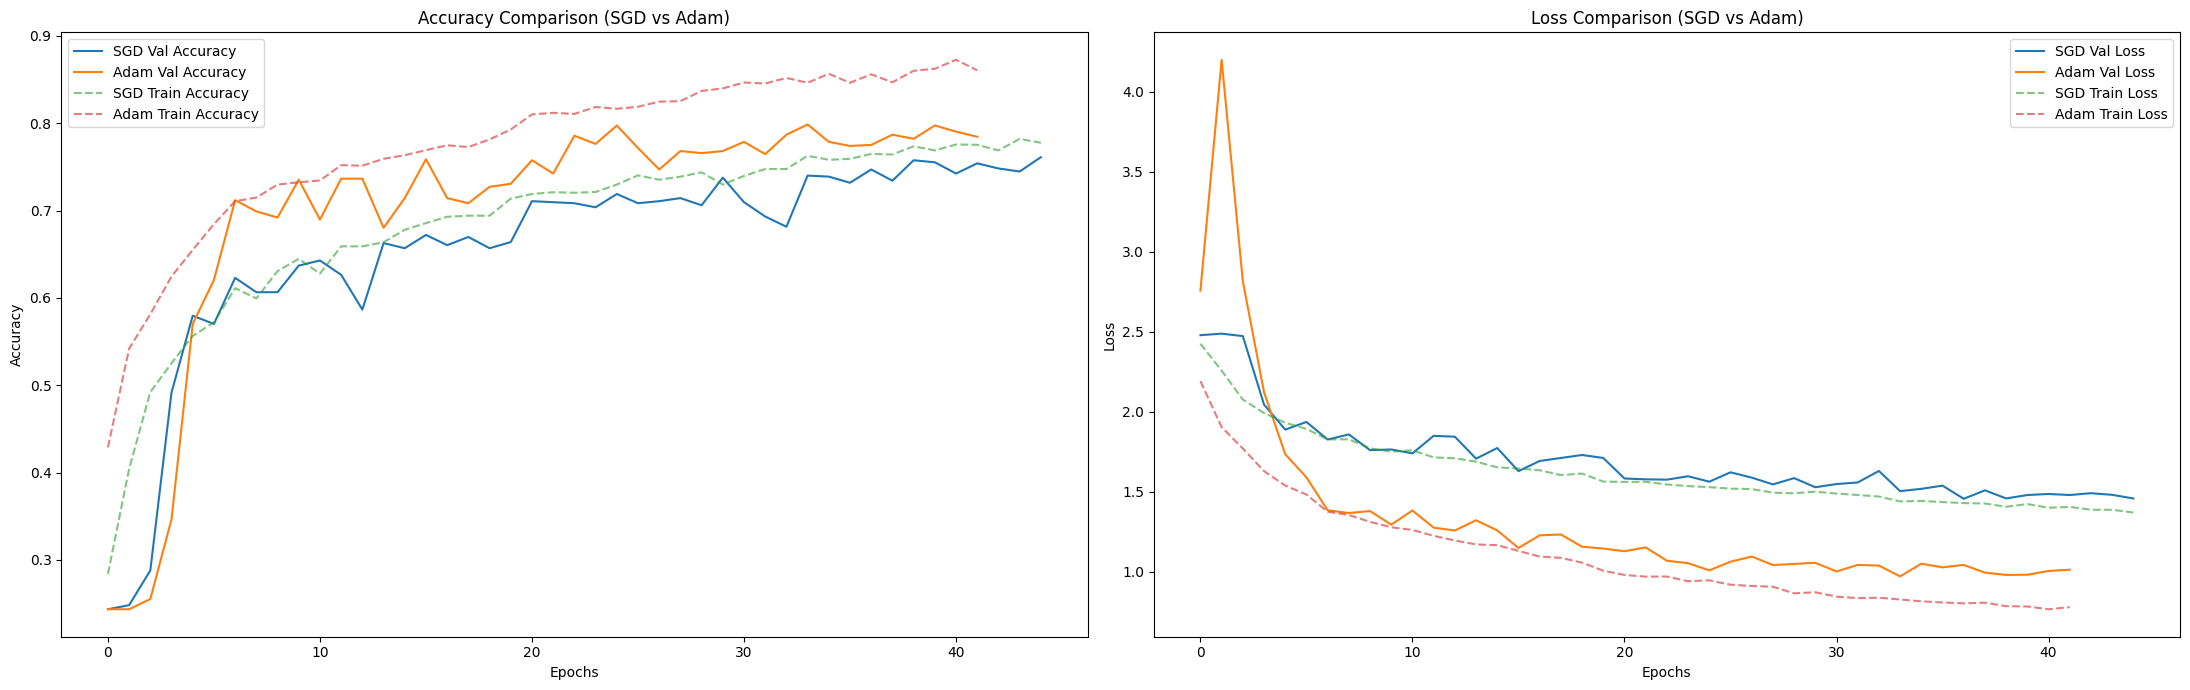

In [ ]:
# Compare SGD vs Adam
plt.figure(figsize=(22, 7))

# Accuracy comparison
plt.subplot(1, 2, 1)

plt.plot(h_sgd.history['val_accuracy'], label='SGD Val Accuracy')
plt.plot(h_adam.history['val_accuracy'], label='Adam Val Accuracy')

plt.plot(h_sgd.history['accuracy'], linestyle='--', alpha=0.6, label='SGD Train Accuracy')
plt.plot(h_adam.history['accuracy'], linestyle='--', alpha=0.6, label='Adam Train Accuracy')

plt.title('Accuracy Comparison (SGD vs Adam)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss comparison
plt.subplot(1, 2, 2)

plt.plot(h_sgd.history['val_loss'], label='SGD Val Loss')
plt.plot(h_adam.history['val_loss'], label='Adam Val Loss')

plt.plot(h_sgd.history['loss'], linestyle='--', alpha=0.6, label='SGD Train Loss')
plt.plot(h_adam.history['loss'], linestyle='--', alpha=0.6, label='Adam Train Loss')

plt.title('Loss Comparison (SGD vs Adam)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

##### **7.3.2: Optimizer Training Time Comparison**

In [ ]:
# Compare optimizer training time
if sgd_time > adam_time:
    print(f"SGD optimizer takes more time: {sgd_time:.2f} seconds")
else:
    print(f"Adam optimizer takes more time: {adam_time:.2f} seconds")

SGD optimizer takes more time: 1158.51 seconds


##### **7.3.3: Optimizer Final Performance Comparison**

In [ ]:
# Predictions for SGD and Adam models
y_pred_sgd = np.argmax(model_sgd.predict(val_data), axis=1)
y_pred_adam = np.argmax(model_adam.predict(val_data), axis=1)
y_true_val = val_data.classes

# Compare optimizer performance
optimizer_results = pd.DataFrame({
    "Optimizer": ["SGD", "Adam"],
    "Accuracy": [
        accuracy_score(y_true_val, y_pred_sgd),
        accuracy_score(y_true_val, y_pred_adam)
    ],
    "Precision": [
        precision_score(y_true_val, y_pred_sgd, average='weighted'),
        precision_score(y_true_val, y_pred_adam, average='weighted')
    ],
    "Recall": [
        recall_score(y_true_val, y_pred_sgd, average='weighted'),
        recall_score(y_true_val, y_pred_adam, average='weighted')
    ],
    "F1": [
        f1_score(y_true_val, y_pred_sgd, average='weighted'),
        f1_score(y_true_val, y_pred_adam, average='weighted')
    ]
})

# Show results table
display(optimizer_results)

27/27 ━━━━━━━━━━━━━━━━━━━━ 6s 180ms/step
27/27 ━━━━━━━━━━━━━━━━━━━━ 7s 242ms/step


,Optimizer,Accuracy,Precision,Recall,F1
0,SGD,0.745902,0.752994,0.745902,0.748298
1,Adam,0.782201,0.783221,0.782201,0.781520


**Experimentation and Comparative Analysis - Optimizer Analysis (SGD vs Adam)**

*   **Performance:** Adam outperformed SGD in the deeper model, achieving higher accuracy (~0.782) and lower validation loss.
*   **Convergence:** Adam converged faster and more stably, highlighting its advantage of adaptive learning rates in complex networks.

### **8: Ablation Study: Effect of Dropout Removal**

#### **8.1: Model Architecture**

In [ ]:
# CNN model without dropout
def build_no_dropout_model(num_classes, regularization=l2(0.001)):

    model = Sequential([

        Input(shape=(128, 128, 3)),

        Conv2D(32, (3,3), activation='relu', padding='same', kernel_regularizer=regularization),
        BatchNormalization(),
        MaxPooling2D(2,2),

        Conv2D(32, (3,3), activation='relu', padding='same', kernel_regularizer=regularization),
        BatchNormalization(),
        MaxPooling2D(2,2),

        Conv2D(64, (3,3), activation='relu', padding='same', kernel_regularizer=regularization),
        BatchNormalization(),
        MaxPooling2D(2,2),

        Conv2D(64, (3,3), activation='relu', padding='same', kernel_regularizer=regularization),
        BatchNormalization(),
        MaxPooling2D(2,2),

        Conv2D(128, (3,3), activation='relu', padding='same', kernel_regularizer=regularization),
        BatchNormalization(),
        MaxPooling2D(2,2),

        Conv2D(128, (3,3), activation='relu', padding='same', kernel_regularizer=regularization),
        BatchNormalization(),
        MaxPooling2D(2,2),

        Flatten(),

        Dense(128, activation='relu', kernel_regularizer=regularization),
        Dense(128, activation='relu', kernel_regularizer=regularization),
        Dense(64, activation='relu', kernel_regularizer=regularization),
        Dense(64, activation='relu', kernel_regularizer=regularization),
        Dense(32, activation='relu', kernel_regularizer=regularization),
        Dense(32, activation='relu', kernel_regularizer=regularization),

        Dense(num_classes, activation='softmax')
    ])

    return model

#### **8.2: Model Training**

In [ ]:
# Build model without dropout
model_no_dropout = build_no_dropout_model(num_classes)

# Compile model
model_no_dropout.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Callbacks
early_stop_ablation = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
reduce_lr_ablation = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=0.00001, verbose=1)

# Start training (ablation study)
print("Starting Training (Ablation Study: No Dropout)...")

start_time = time.time()

h_no = model_no_dropout.fit(
    train_data,
    validation_data=val_data,
    epochs=50,
    class_weight=class_weight_dict,
    callbacks=[early_stop_ablation, reduce_lr_ablation]
)

# Training time
no_dropout_time = time.time() - start_time

print(f"Total training time (No-Dropout): {no_dropout_time:.2f} seconds")

Starting Training (Ablation Study: No Dropout)...
Epoch 1/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 44s 311ms/step - accuracy: 0.4730 - loss: 2.0639 - val_accuracy: 0.2436 - val_loss: 2.8660 - learning_rate: 0.0010
Epoch 2/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 25s 237ms/step - accuracy: 0.5904 - loss: 1.7479 - val_accuracy: 0.2600 - val_loss: 2.3775 - learning_rate: 0.0010
Epoch 3/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 24s 223ms/step - accuracy: 0.6299 - loss: 1.5966 - val_accuracy: 0.2927 - val_loss: 2.9535 - learning_rate: 0.0010
Epoch 4/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 25s 233ms/step - accuracy: 0.6743 - loss: 1.4515 - val_accuracy: 0.5328 - val_loss: 1.7068 - learning_rate: 0.0010
Epoch 5/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 26s 239ms/step - accuracy: 0.6947 - loss: 1.3386 - val_accuracy: 0.6194 - val_loss: 1.5559 - learning_rate: 0.0010
Epoch 6/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 26s 242ms/step - accuracy: 0.7099 - loss: 1.2790 - val_accuracy: 0.6464 - val_loss: 1.3892 - learning_rate: 0.0010
Epoch 7/50
107/107 ━

#### **8.3: Ablation Comparison Graph**

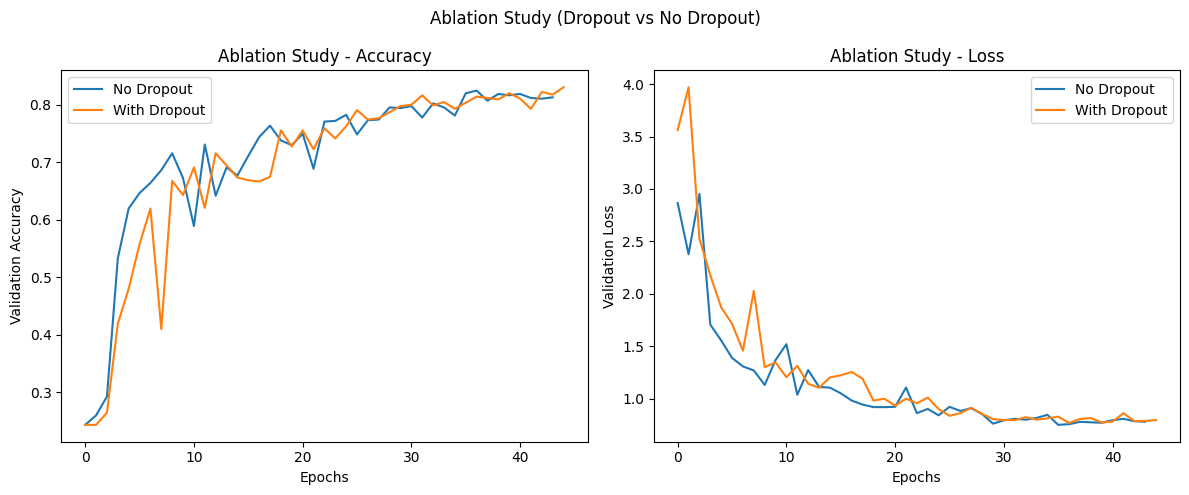

In [ ]:
# Ablation study comparison (Dropout vs No Dropout)
plt.figure(figsize=(12,5))

# Accuracy comparison
plt.subplot(1,2,1)
plt.plot(h_no.history['val_accuracy'], label='No Dropout')
plt.plot(h2.history['val_accuracy'], label='With Dropout')
plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.title("Ablation Study - Accuracy")
plt.legend()

# Loss comparison
plt.subplot(1,2,2)
plt.plot(h_no.history['val_loss'], label='No Dropout')
plt.plot(h2.history['val_loss'], label='With Dropout')
plt.xlabel("Epochs")
plt.ylabel("Validation Loss")
plt.title("Ablation Study - Loss")
plt.legend()

# Overall title
plt.suptitle("Ablation Study (Dropout vs No Dropout)")
plt.tight_layout()
plt.show()

#### **8.4: Ablation Classification Report**

In [ ]:
# Predictions
y_pred = model_no_dropout.predict(val_data)
y_pred_classes = np.argmax(y_pred, axis=1)

# True labels
y_true = val_data.classes

# Class names
class_labels = list(val_data.class_indices.keys())

# Evaluation report
report = classification_report(y_true, y_pred_classes, target_names=class_labels)

# Print results
print("Classification Report (Ablation Study):\n")
print(report)

27/27 ━━━━━━━━━━━━━━━━━━━━ 7s 248ms/step
Classification Report (Ablation Study):

              precision    recall  f1-score   support

       daisy       0.96      0.85      0.90       151
   dandelion       0.86      0.86      0.86       208
        rose       0.78      0.72      0.75       155
   sunflower       0.80      0.88      0.84       145
       tulip       0.77      0.82      0.79       195

    accuracy                           0.83       854
   macro avg       0.83      0.83      0.83       854
weighted avg       0.83      0.83      0.83       854



**Experimentation and Comparative Analysis - Ablation Study (Dropout Removal)**

*   **Performance Change:** Removing dropout slightly improved validation accuracy from the deeper model's 82% to the no-dropout model's 83%. This indicates that the original dropout rates might have been too aggressive or that the combination of L2 regularization and Batch Normalization was sufficient for regularizing this specific model and dataset.

*   **Observation:** The marginal improvement suggests that for this architecture and dataset, L2 regularization and Batch Normalization effectively managed overfitting, and additional dropout either hindered learning or was redundant.

### **Part B: Fine-Tuning a Pre-Trained Model (Transfer Learning)**

### **9: Transfer Learning using MobileNetV2**

#### **9.1: Configuration for Transfer Learning**

In [ ]:
# Image size for transfer learning model
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32

# Number of classes
NUM_CLASSES = len(classes)

# Setup info
print(f"Transfer Learning Setup: {NUM_CLASSES} classes, Input Size: {IMG_HEIGHT}x{IMG_WIDTH}")

Transfer Learning Setup: 5 classes, Input Size: 224x224


#### **9.2: Data Generators**

In [ ]:
# Training data generator
train_datagen_tl = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.2
)

# Validation data generator
val_datagen_tl = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input,
    validation_split=0.2
)

# Training set
train_generator_tl = train_datagen_tl.flow_from_directory(
    base_data_for_split,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

# Validation set
validation_generator_tl = val_datagen_tl.flow_from_directory(
    base_data_for_split,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

# Done message
print("Data generators for Transfer Learning created successfully.")

Found 3423 images belonging to 5 classes.
Found 854 images belonging to 5 classes.
Data generators for Transfer Learning created successfully.


#### **9.3: Loading & Adapting Pre-trained MobileNetV2**

In [ ]:
# Load MobileNetV2 as base model
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)
)

# Freeze base model layers
base_model.trainable = False

# Build transfer learning model
inputs = tf.keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3))
x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.3)(x)
x = BatchNormalization()(x)
outputs = Dense(NUM_CLASSES, activation='softmax')(x)

model_tl = Model(inputs, outputs)

# Compile model
model_tl.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])

# Show model structure
model_tl.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_24          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,588,229 (9.87 MB)

 Trainable params: 329,733 (1.26 MB)

 Non-trainable params: 2,258,496 (8.62 MB)

#### **9.4: Feature Extraction**

In [ ]:
# Callbacks for feature extraction training
early_stop_fe = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)
reduce_lr_fe = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)

# Start training (feature extraction)
print("Starting MobileNetV2 Feature Extraction...")
start_time = time.time()

history_fe = model_tl.fit(
    train_generator_tl,
    validation_data=validation_generator_tl,
    epochs=20,
    class_weight=class_weight_dict,
    callbacks=[early_stop_fe, reduce_lr_fe],
    verbose=1
)

# Training time
feature_extraction_time = time.time() - start_time
print(f"Total training time (Feature Extraction): {feature_extraction_time:.2f} seconds")

Starting MobileNetV2 Feature Extraction...
Epoch 1/20
107/107 ━━━━━━━━━━━━━━━━━━━━ 49s 456ms/step - accuracy: 0.9141 - loss: 0.2512 - val_accuracy: 0.9087 - val_loss: 0.2750 - learning_rate: 1.0000e-05
Epoch 2/20
107/107 ━━━━━━━━━━━━━━━━━━━━ 48s 447ms/step - accuracy: 0.9202 - loss: 0.2357 - val_accuracy: 0.9098 - val_loss: 0.2664 - learning_rate: 1.0000e-05
Epoch 3/20
107/107 ━━━━━━━━━━━━━━━━━━━━ 48s 448ms/step - accuracy: 0.9273 - loss: 0.2197 - val_accuracy: 0.9098 - val_loss: 0.2676 - learning_rate: 1.0000e-05
Epoch 4/20
107/107 ━━━━━━━━━━━━━━━━━━━━ 49s 451ms/step - accuracy: 0.9226 - loss: 0.2289 - val_accuracy: 0.9122 - val_loss: 0.2597 - learning_rate: 1.0000e-05
Epoch 5/20
107/107 ━━━━━━━━━━━━━━━━━━━━ 47s 443ms/step - accuracy: 0.9299 - loss: 0.2075 - val_accuracy: 0.9098 - val_loss: 0.2627 - learning_rate: 1.0000e-05
Epoch 6/20
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 439ms/step - accuracy: 0.9338 - loss: 0.1971
Epoch 6: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06

#### **9.5: Feature Extraction Accuracy and Loss Curves**



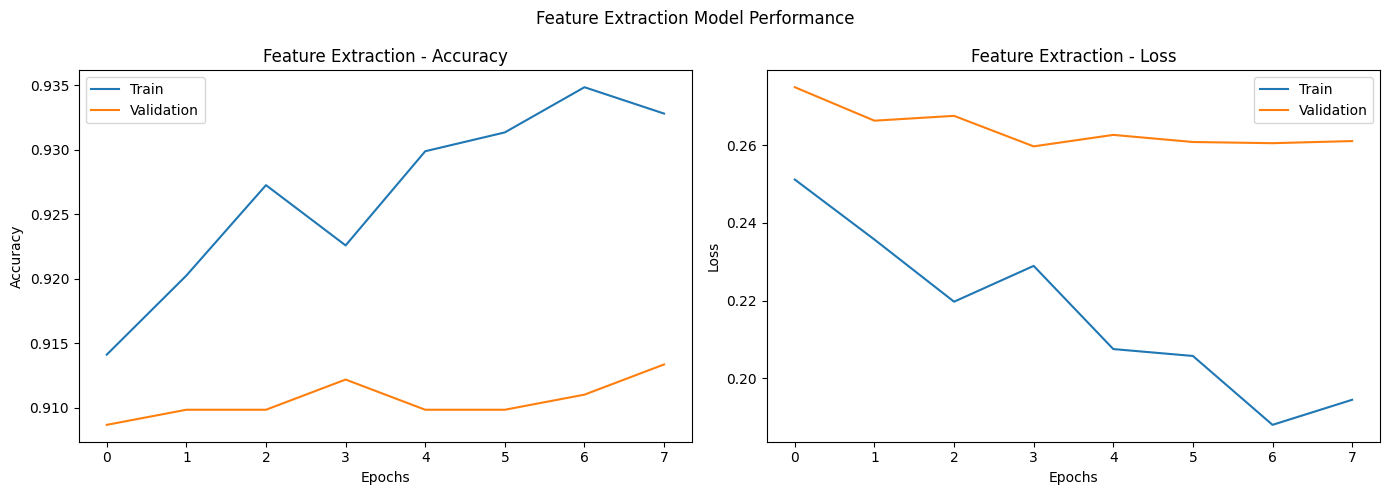

In [ ]:
# Plot feature extraction performance
plt.figure(figsize=(14,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history_fe.history['accuracy'], label='Train')
plt.plot(history_fe.history['val_accuracy'], label='Validation')

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Feature Extraction - Accuracy")
plt.legend()

# Loss
plt.subplot(1,2,2)
plt.plot(history_fe.history['loss'], label='Train')
plt.plot(history_fe.history['val_loss'], label='Validation')

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Feature Extraction - Loss")
plt.legend()

# Overall title
plt.suptitle("Feature Extraction Model Performance")
plt.tight_layout()
plt.show()

#### **9.6: Evaluating MobileNetV2 (Feature Extraction)**

In [ ]:
# Predictions on validation set (Feature Extraction)
print("Evaluating MobileNetV2 (Feature Extraction) on Validation Set\n")

Y_pred_tl_fe = model_tl.predict(validation_generator_tl)
y_pred_tl_fe = np.argmax(Y_pred_tl_fe, axis=1)
y_true_tl_fe = validation_generator_tl.classes

# Classification report
print("MobileNetV2 (Feature Extraction) Evaluation:")
print(classification_report(y_true_tl_fe, y_pred_tl_fe, target_names=classes))

Evaluating MobileNetV2 (Feature Extraction) on Validation Set

27/27 ━━━━━━━━━━━━━━━━━━━━ 13s 298ms/step
MobileNetV2 (Feature Extraction) Evaluation:
              precision    recall  f1-score   support

       daisy       0.91      0.92      0.91       151
   dandelion       0.93      0.93      0.93       208
        rose       0.91      0.88      0.90       155
   sunflower       0.88      0.93      0.91       145
       tulip       0.92      0.90      0.91       195

    accuracy                           0.91       854
   macro avg       0.91      0.91      0.91       854
weighted avg       0.91      0.91      0.91       854



#### **9.7: Fine-Tuning**


In [ ]:
# Unfreeze base model for fine-tuning
base_model.trainable = True

# Freeze early layers, fine-tune last layers
fine_tune_at = len(base_model.layers) - 60
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Recompile model with low learning rate
model_tl.compile(optimizer=Adam(learning_rate=1e-5), loss='categorical_crossentropy', metrics=['accuracy'])

# Callbacks for fine-tuning
early_stop_ft = EarlyStopping( monitor='val_loss', patience=6, restore_best_weights=True)

reduce_lr_ft = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-7, verbose=1)

# Start fine-tuning
print("Starting MobileNetV2 Fine-Tuning...")
start_time = time.time()

history_ft = model_tl.fit(
    train_generator_tl,
    validation_data=validation_generator_tl,
    epochs=50,
    class_weight=class_weight_dict,
    callbacks=[early_stop_ft, reduce_lr_ft],
    verbose=1
)

# Training time
fine_tuning_time = time.time() - start_time
print(f"Total training time (Fine-Tuning): {fine_tuning_time:.2f} seconds")

Starting MobileNetV2 Fine-Tuning...
Epoch 1/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 91s 626ms/step - accuracy: 0.9226 - loss: 0.2110 - val_accuracy: 0.9180 - val_loss: 0.2562 - learning_rate: 1.0000e-05
Epoch 2/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 48s 444ms/step - accuracy: 0.9346 - loss: 0.1990 - val_accuracy: 0.9133 - val_loss: 0.2566 - learning_rate: 1.0000e-05
Epoch 3/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 49s 459ms/step - accuracy: 0.9311 - loss: 0.1959 - val_accuracy: 0.9110 - val_loss: 0.2595 - learning_rate: 1.0000e-05
Epoch 4/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 431ms/step - accuracy: 0.9546 - loss: 0.1512
Epoch 4: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.
107/107 ━━━━━━━━━━━━━━━━━━━━ 48s 450ms/step - accuracy: 0.9451 - loss: 0.1655 - val_accuracy: 0.9087 - val_loss: 0.2668 - learning_rate: 1.0000e-05
Epoch 5/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 51s 475ms/step - accuracy: 0.9398 - loss: 0.1769 - val_accuracy: 0.9087 - val_loss: 0.2635 - learning_rate: 2.0000e-06
Epoch 6/50
107/

#### **9.8: Plot Accuracy and Loss Curves for Fine-Tuned MobileNetV2**

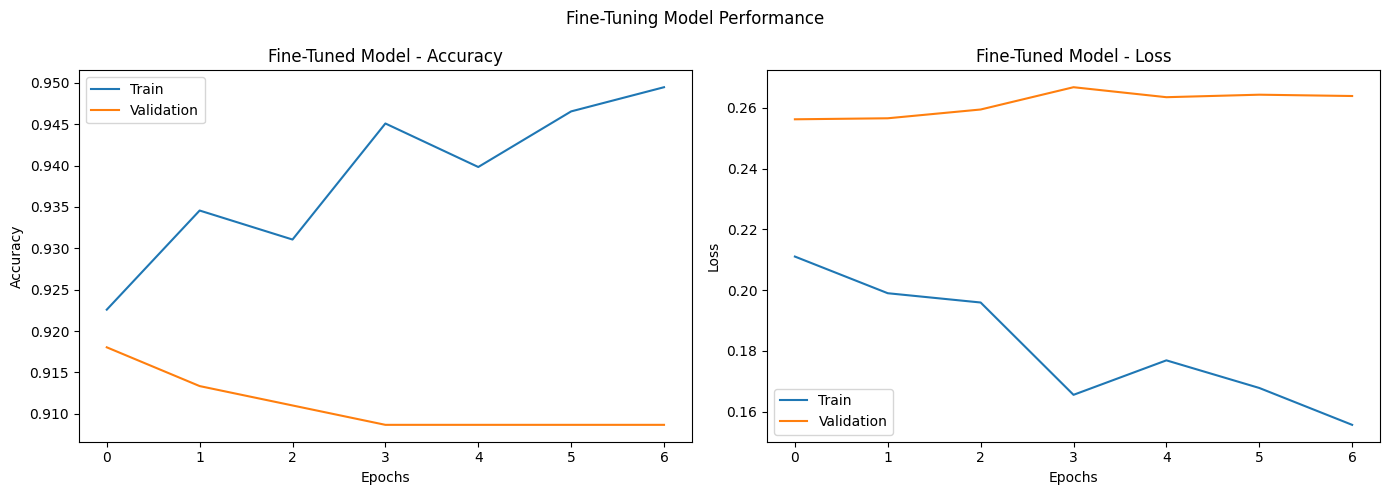

In [ ]:
# Plot fine-tuning performance
plt.figure(figsize=(14,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history_ft.history['accuracy'], label='Train')
plt.plot(history_ft.history['val_accuracy'], label='Validation')

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Fine-Tuned Model - Accuracy")
plt.legend()

# Loss
plt.subplot(1,2,2)
plt.plot(history_ft.history['loss'], label='Train')
plt.plot(history_ft.history['val_loss'], label='Validation')

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Fine-Tuned Model - Loss")
plt.legend()

# Overall title
plt.suptitle("Fine-Tuning Model Performance")
plt.tight_layout()
plt.show()

#### **9.9: Evaluating MobileNetV2 (Fine-Tuned)**

In [ ]:
# Evaluate fine-tuned model
print("Evaluating Fine-tuned MobileNetV2 on Validation Set\n")

Y_pred_tl = model_tl.predict(validation_generator_tl)
y_pred_tl = np.argmax(Y_pred_tl, axis=1)
y_true_tl = validation_generator_tl.classes

# Classification report
print("Classification Report - Fine-tuned MobileNetV2:")
print(classification_report(y_true_tl, y_pred_tl, target_names=classes))

Evaluating Fine-tuned MobileNetV2 on Validation Set

27/27 ━━━━━━━━━━━━━━━━━━━━ 13s 258ms/step
Classification Report - Fine-tuned MobileNetV2:
              precision    recall  f1-score   support

       daisy       0.91      0.92      0.92       151
   dandelion       0.93      0.93      0.93       208
        rose       0.94      0.90      0.92       155
   sunflower       0.88      0.94      0.91       145
       tulip       0.92      0.91      0.91       195

    accuracy                           0.92       854
   macro avg       0.92      0.92      0.92       854
weighted avg       0.92      0.92      0.92       854



In [ ]:
# Store fine-tuned predictions and true labels
y_pred_ft = y_pred_tl
y_true_ft = y_true_tl

#### **9.10: Evaluating MobileNetV2 (Fine-Tuned)**

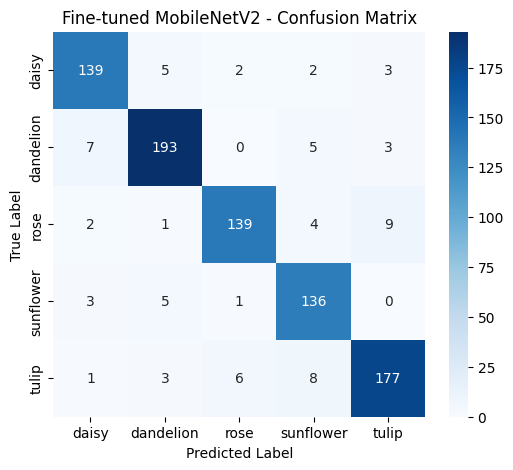

In [ ]:
# Class names
classes = list(validation_generator_tl.class_indices.keys())

# Confusion matrix
cm_ft = confusion_matrix(y_true_tl, y_pred_tl)

# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(cm_ft, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes)

plt.title('Fine-tuned MobileNetV2 - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.show()

#### **9.11: Save the Model**

In [ ]:
# Save fine-tuned model
model_tl.save('mobilenetv2_finetuned_flower_classification.h5')

# Confirmation message
print("Fine-tuned MobileNetV2 model saved successfully!")

Fine-tuned MobileNetV2 model saved successfully!


#### **9.12: Visual Inference of Images (Fine-Tuned)**

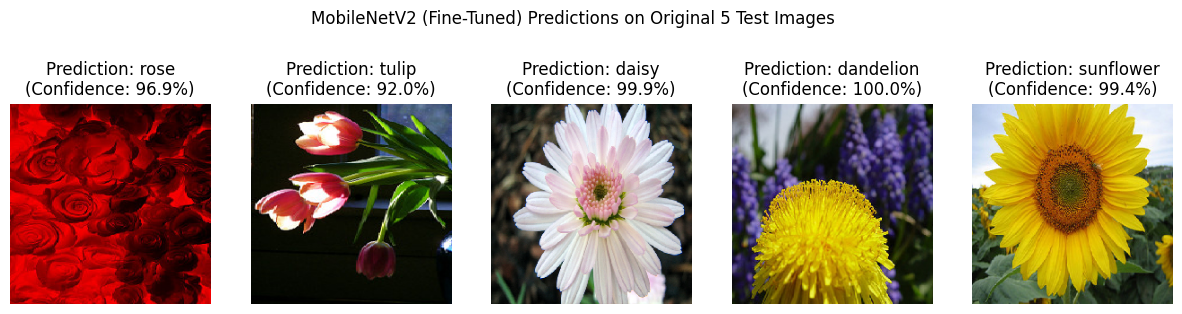

In [ ]:
# Plot predictions on test images (Fine-tuned model)
plt.figure(figsize=(15, 4))

for i, img_name in enumerate(test_images):
    img_path = os.path.join(original_test_dir, img_name)
    img = load_img(img_path, target_size=(224, 224))
    img_array = img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # Model prediction
    prediction = model_tl.predict(img_array, verbose=0)
    pred_idx = np.argmax(prediction)
    pred_class = classes[pred_idx]
    confidence = np.max(prediction) * 100

    # Display result
    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(f"Prediction: {pred_class}\n(Confidence: {confidence:.1f}%)")
    plt.axis('off')

# Title
plt.suptitle("MobileNetV2 (Fine-Tuned) Predictions on Original 5 Test Images")
plt.show()

### **10: Final Model Comparison Table**

In [ ]:
# Final model comparison table
results = pd.DataFrame({
    "Model": ["Baseline", "Deep", "MobileNetV2", "Fine-Tuned MobileNetV2"],
    "Accuracy": [
        accuracy_score(y_true_base, y_pred_base),
        accuracy_score(y_true_deep, y_pred_deep),
        accuracy_score(y_true_tl_fe, y_pred_tl_fe),
        accuracy_score(y_true_ft, y_pred_ft)
    ],
    "Precision": [
        precision_score(y_true_base, y_pred_base, average='weighted'),
        precision_score(y_true_deep, y_pred_deep, average='weighted'),
        precision_score(y_true_tl_fe, y_pred_tl_fe, average='weighted'),
        precision_score(y_true_ft, y_pred_ft, average='weighted')
    ],
    "Recall": [
        recall_score(y_true_base, y_pred_base, average='weighted'),
        recall_score(y_true_deep, y_pred_deep, average='weighted'),
        recall_score(y_true_tl_fe, y_pred_tl_fe, average='weighted'),
        recall_score(y_true_ft, y_pred_ft, average='weighted')
    ],
    "F1": [
        f1_score(y_true_base, y_pred_base, average='weighted'),
        f1_score(y_true_deep, y_pred_deep, average='weighted'),
        f1_score(y_true_tl_fe, y_pred_tl_fe, average='weighted'),
        f1_score(y_true_ft, y_pred_ft, average='weighted')
    ]
})

# Show results
display(results)

,Model,Accuracy,Precision,Recall,F1
0,Baseline,0.729508,0.737684,0.729508,0.730046
1,Deep,0.818501,0.817438,0.818501,0.817530
2,MobileNetV2,0.912178,0.912515,0.912178,0.912161
3,Fine-Tuned MobileNetV2,0.918033,0.918716,0.918033,0.918099


### **Model Evaluation and Prediction - Transfer Learning Performance**

*   **Transfer Learning vs. Scratch Models:** MobileNetV2 (feature extraction and fine-tuned) significantly outperformed all models trained from scratch, achieving ~0.912–0.918 accuracy compared to the baseline’s ~0.73.
*   **Conclusion:** Transfer learning effectively leverages pre-trained features, resulting in higher accuracy, better generalisation, and efficient training for this dataset.



### **Experimentation and Comparative Analysis - Challenges and Observations**

*   **Challenges:** The initial deeper model with dropout did not show a significant improvement, highlighting the importance of tuning regularization techniques. SGD also showed slower convergence and lower performance compared to Adam.
*   **Hardware Acceleration:** All models were trained using Google Colab GPU acceleration, enabling faster computation for deep learning tasks.
*   **Total Training Times:**
    *   Baseline: 692.51s
    *   Deeper: 1208.09s
    *   Deeper (SGD): 1158.51s
    *   Deeper (Adam): 1095.04
    *   Deeper (No-Dropout): 1135.61s
    *   MobileNetV2 (Feature Extraction): 390.44s
    *   MobileNetV2 (Fine-Tuned): 385.79s

### **Conclusion**

This project showed that transfer learning with MobileNetV2 significantly outperformed custom CNN models for flower species classification, achieving higher accuracy and better generalization. The fine-tuned MobileNetV2 model was the most effective and efficient approach. The ablation study also highlighted the importance of proper regularization, as removing dropout improved performance in the deeper CNN, suggesting initial over-regularization.